# Customer concentration and revenue protection

Does selecting merchants with less dependence on shared customers improve resilience? We distinguish concentration, observed performance, and hypothetical spending shocks. Expected return remains mean monthly gross fees; every selection contains exactly 100 eligible merchants. This study is retrospective.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown
root = Path.cwd() if (Path.cwd() / 'code').exists() else Path.cwd().parent
sys.path.insert(0, str(root / 'code'))
import customer_concentration as c
out = c.OUT
c.report_stage()
report_path = out / 'findings.md'
report_text = report_path.read_text(encoding='utf-8').replace('python code/customer_concentration.py', 'python code/customer_concentration_serial.py')
report_text += '\nThe recommended serial entry point runs one numerical worker at a time and lowers Windows process priority. It retains the original single-threaded optimizer loop and the original 20-thread BLAS reduction setting around that loop, under the 4 GiB memory and 20% CPU ceilings. The May and June 2022 hindsight cases at the 95% fee floor instead retain the one-thread outer setting used by their original serial recovery run. Run one stage command at a time. It preserves the frozen scientific settings and solver budgets. Reproduction requires exact identifiers, ranks, decisions, schema and missingness; derived floating values allow relative tolerance 1e-12 and absolute tolerance 1e-15 for documented thread-order rounding. Frozen result tables remain unchanged, and accepted differences are logged. Parquet may normalize an object-Boolean column or discard a non-default row index. The verifier restores the original in-memory schema only when its exact original audit hash and a lossless round trip both pass; it never changes saved values or their checksums. The original module can otherwise use parallel date workers.\n'
report_path.write_text(report_text, encoding='utf-8')
settings = json.loads((out / 'protocol.json').read_text())
display(pd.Series({k: settings[k] for k in ['count','retentions','windows','expected_return','retrospective','untouched_holdout']}))

Concentration findings and plots written.


count                                                     100
retentions                          [0.995, 0.99, 0.98, 0.95]
windows                                            [26w, 52w]
expected_return      expanding complete-month mean gross fees
retrospective                                            True
untouched_holdout                                       False
dtype: object

## Audited customer identity

We join transaction user IDs to canonical consumer IDs. Names, addresses and demographic attributes are unused. Customer exposures reconcile with the existing merchant-day and merchant-month panels. Unknown merchants remain outside fee selection; their transactions can establish customer activity elsewhere in the observed network.

In [2]:
audit = json.loads((out / 'preparation.json').read_text())
display(pd.Series({k: audit[k] for k in ['total_orders','known_orders','unknown_merchant_orders','source_reconciled','daily_monthly_reconciled']}))
display(pd.read_parquet(out / 'availability.parquet'))

total_orders                13440766
known_orders                12890819
unknown_merchant_orders       549947
source_reconciled               True
daily_monthly_reconciled        True
dtype: object

,as_of,window,available
0,2021-11-30,26w,True
1,2021-11-30,52w,False
2,2021-12-31,26w,True
3,2021-12-31,52w,False
4,2022-01-31,26w,True
5,2022-01-31,52w,False
6,2022-02-28,26w,True
7,2022-02-28,52w,True
8,2022-03-31,26w,True
9,2022-03-31,52w,True


## Measuring the whole portfolio

Customer share is its estimated fee contribution across **all selected merchants**, divided by portfolio expected fees. HHI is the sum of squared shares; its reciprocal is the effective customer count. HHI contains an individual-merchant term and a shared-customer term. Scaling all fees down does not reduce HHI.

The individual control minimizes the first term. The shared method minimizes both. Neither is a forecast of customer departure. The September plots describe unscored selections.

For historical customer fees \(f_{ci}\), the agreed monthly expected fees \(\mu_i\), and a binary merchant selection \(z_i\):

\[
p_{ci}=\frac{f_{ci}}{\sum_c f_{ci}},\qquad A_{ci}=\mu_i p_{ci},\qquad
s_c=\frac{\sum_i A_{ci}z_i}{\sum_i\mu_i z_i}.
\]

\[
\mathrm{HHI}=\sum_c s_c^2
=\underbrace{\sum_i w_i^2\sum_c p_{ci}^2}_{\text{individual contribution}}
+\underbrace{2\sum_{i<j}w_iw_j\sum_c p_{ci}p_{cj}}_{\text{shared-customer contribution}},
\qquad w_i=\frac{\mu_i z_i}{\sum_j\mu_jz_j}.
\]

Both methods retain exactly 100 eligible merchants and the specified fraction of baseline expected fees. The control minimizes only the individual contribution; the full method minimizes their sum. The optimization uses the exact normalization \(t=1/(\mu^\top z)\), \(v_i=tz_i\), with binary product constraints. Feasible solutions and genuine lower bounds remain visible when a search is uncertified. Observed historical-fee concentration is exported separately from these expected-fee exposures.


The customer identity map includes inactive customers. We also compare the baseline customer count with customers actually observed at eligible merchants. Reaching the same customer population does not imply identical concentration: fee shares can still become more balanced. With N observed customers, HHI cannot fall below 1/N, attained only when all fee shares are equal. The September baseline already reaches all 24,081 customers in its eligible historical pool, so perfectly balancing those same customers could reduce its estimated HHI by at most about 11.67%, even before merchant-selection and revenue constraints. This is a historical mathematical bound, not a future-performance guarantee.

In the independent customer-loss scenario, the shared-customer term is the part of modeled loss variance caused by overlapping exposure. Its share of total HHI quantifies the variance omitted by a calculation using only individual-merchant terms. The square root of total HHI divided by the individual term gives the corresponding standard-deviation ratio for the same exposure matrix. This describes a conditional model, not observed cash-flow volatility or an optimization gain.

,method,retention,expected_monthly_fees,estimated_hhi,estimated_effective_customers,estimated_top_100_share,estimated_shared_hhi,certified
117,revenue_only,1.000,1.666400e+06,0.000047,21269.845571,0.013400,0.000041,False
118,individual,0.995,1.658314e+06,0.000047,21385.850995,0.013429,0.000041,True
119,shared,0.995,1.658314e+06,0.000047,21385.850995,0.013429,0.000041,True
120,individual,0.990,1.649898e+06,0.000046,21668.593110,0.011579,0.000041,True
121,shared,0.990,1.650114e+06,0.000046,21670.134046,0.011567,0.000041,True
122,individual,0.980,1.633235e+06,0.000046,21970.402455,0.010200,0.000041,True
123,shared,0.980,1.633149e+06,0.000046,21972.320696,0.010177,0.000041,True
124,individual,0.950,1.583393e+06,0.000045,22361.089967,0.009253,0.000041,True
125,shared,0.950,1.583336e+06,0.000045,22361.547671,0.009224,0.000041,False


,as_of,window,identity_map_customers,eligible_active_customers,baseline_active_customers,baseline_customer_coverage_pct,eligible_customers_outside_baseline
0,2021-11-30,26w,499999,24081,24081,100.0,0
1,2021-12-31,26w,499999,24081,24081,100.0,0
2,2022-01-31,26w,499999,24081,24081,100.0,0
3,2022-02-28,26w,499999,24081,24081,100.0,0
4,2022-02-28,52w,499999,24081,24081,100.0,0
5,2022-03-31,26w,499999,24081,24081,100.0,0
6,2022-03-31,52w,499999,24081,24081,100.0,0
7,2022-04-30,26w,499999,24081,24081,100.0,0
8,2022-04-30,52w,499999,24081,24081,100.0,0
9,2022-05-31,26w,499999,24081,24081,100.0,0


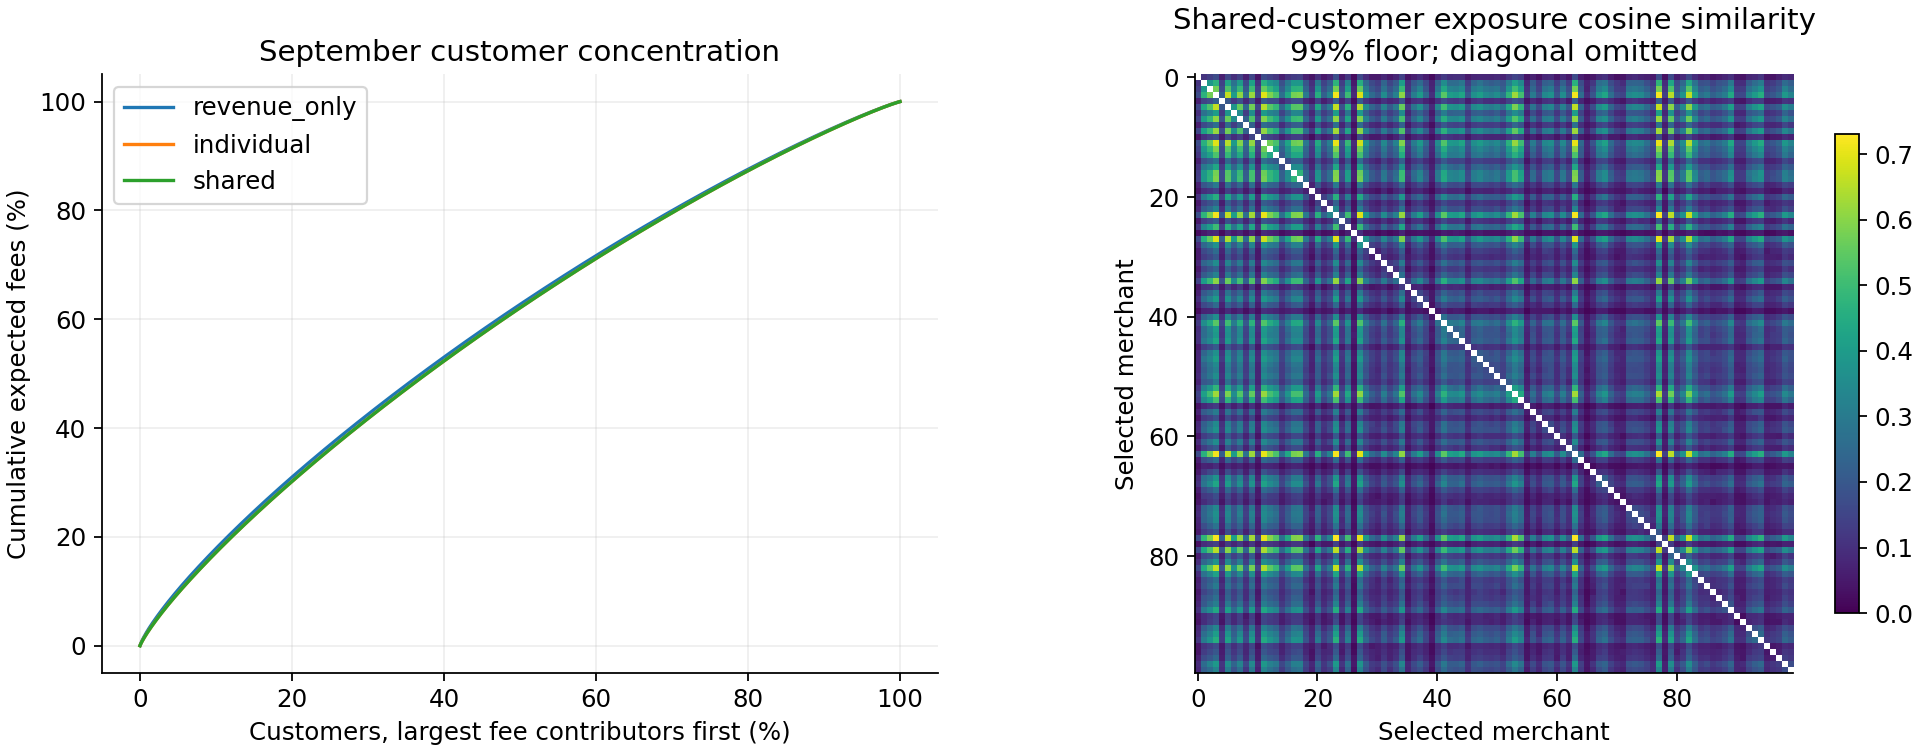

September: shared-customer share of estimated HHI (%)              87.347456
Conditional loss SD: full / individual terms only                   2.811325
Historical HHI reduction ceiling from equal customer shares (%)    11.673745
dtype: float64

In [3]:
estimates = pd.read_parquet(out / 'unscored_estimates.parquet')
latest = estimates.loc[estimates.as_of.eq('2022-09-30') & estimates.window.eq('26w')]
display(latest[['method','retention','expected_monthly_fees','estimated_hhi','estimated_effective_customers','estimated_top_100_share','estimated_shared_hhi','certified']])
display(pd.read_parquet(out / 'historical_customer_population.parquet'))
display(Image(filename=str(out / 'plots/customer_exposure.png')))
baseline = latest.loc[latest.method.eq('revenue_only')].iloc[0]
population = pd.read_parquet(out / 'historical_customer_population.parquet')
latest_population = population.loc[population.as_of.eq('2022-09-30') & population.window.eq('26w')].iloc[0]
display(pd.Series({
    'September: shared-customer share of estimated HHI (%)': 100 * baseline.estimated_shared_hhi / baseline.estimated_hhi,
    'Conditional loss SD: full / individual terms only': (baseline.estimated_hhi / baseline.estimated_individual_hhi) ** 0.5,
    'Historical HHI reduction ceiling from equal customer shares (%)': 100 * (1 - baseline.estimated_effective_customers / latest_population.eligible_active_customers),
}))

## Estimated and subsequent concentration

The primary comparison covers eight chronological selection dates. Outcomes use the following three complete months. The 52-week sensitivity is restricted to the five common dates. The predeclared concentration screen requires at least a 5% average future HHI reduction, average actual fee retention at or above the specified floor, and lower HHI together with the actual fee floor in at least six of the eight primary tests.

Observed weekly fee standard deviation and standard deviation divided by weekly mean are reported separately from customer HHI. Downside uses the same frozen 26-week baseline income reference for every method and history length.

The revenue-only baseline has zero common-reference downside at the May and June 2022 origins. Those zero-downside ties cannot count as improvements; the predeclared six-of-eight consistency rule therefore requires improvement at all six remaining origins. This does not change the rule or exclude the two zero-downside periods from the summaries.

,method,retention,mean_actual_fee_retention_pct,mean_hhi_reduction_pct,hhi_joint_successes,concentration_benefit
0,individual,0.950,94.979007,9.978399,5.0,False
1,individual,0.980,98.028826,6.742327,4.0,False
2,individual,0.990,99.018415,4.180579,5.0,False
3,individual,0.995,99.550983,1.555922,4.0,False
4,shared,0.950,94.970343,9.967090,5.0,False
5,shared,0.980,98.026973,6.741425,5.0,False
6,shared,0.990,99.020301,4.183662,6.0,False
7,shared,0.995,99.552305,1.549815,4.0,False


,method,retention,mean_sd_reduction_pct,mean_cv_reduction_pct,normalized_downside_reduction_pct,investigate_downside
0,individual,0.950,5.235121,0.214446,-28.649594,False
1,individual,0.980,2.165551,0.180744,-10.743978,False
2,individual,0.990,1.285239,0.299079,-5.336080,False
3,individual,0.995,-1.831429,-2.281896,-2.934497,False
4,shared,0.950,5.218082,0.189285,-28.705088,False
5,shared,0.980,2.120728,0.138224,-10.714123,False
6,shared,0.990,1.341803,0.357855,-5.307530,False
7,shared,0.995,-1.569059,-2.021636,-2.941238,False


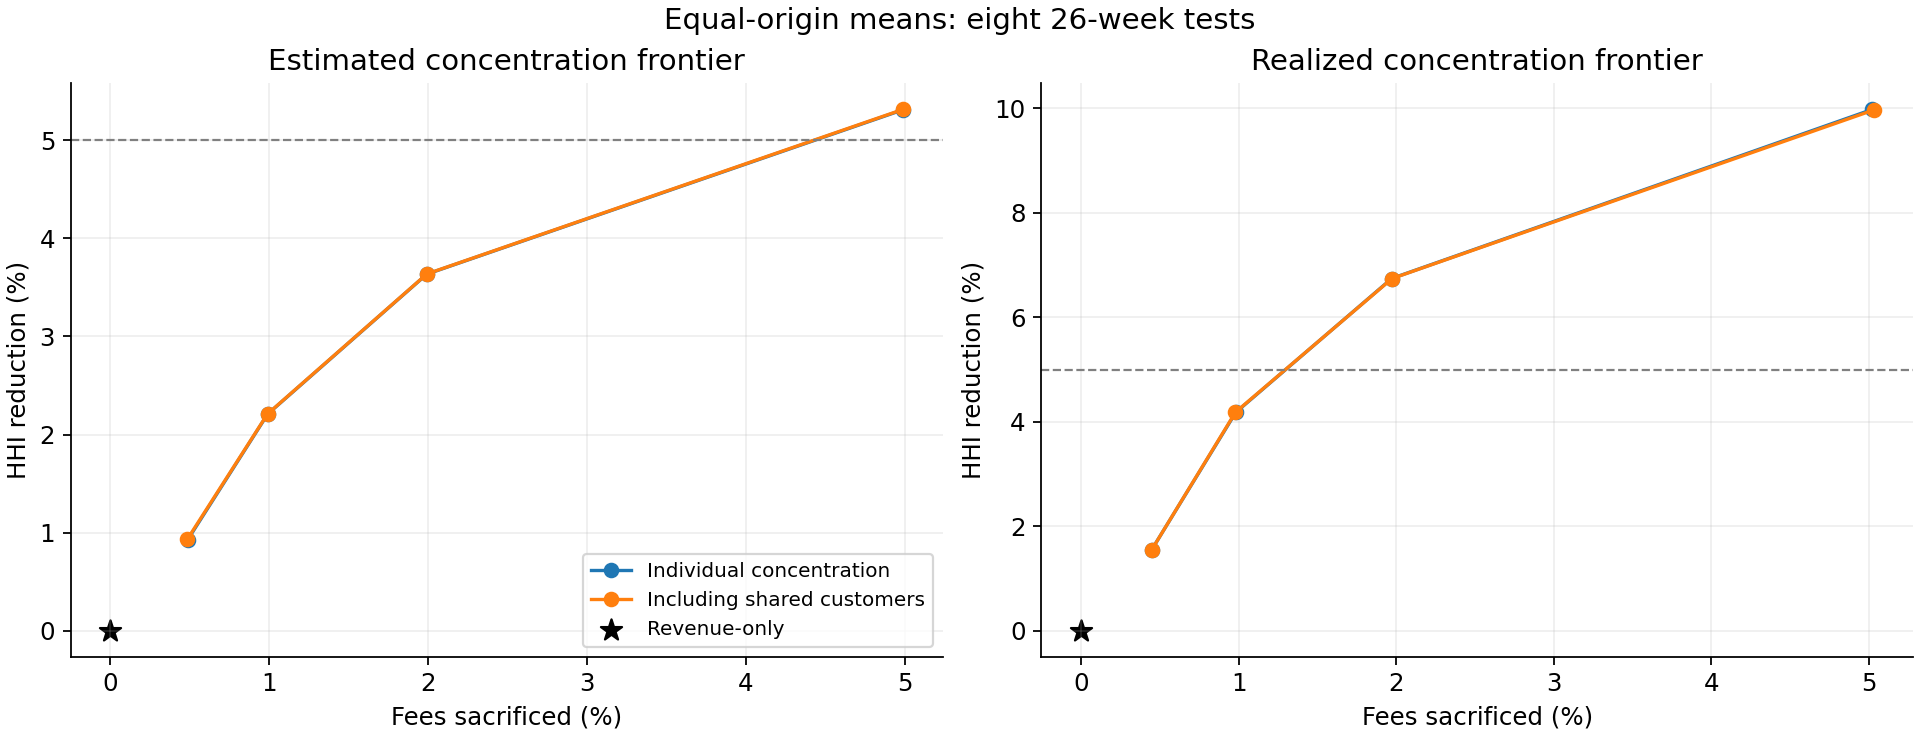

In [4]:
summary = pd.read_parquet(out / 'summary.parquet')
primary = summary.loc[summary.comparison.eq('primary_26w_eight')]
display(primary[['method','retention','mean_actual_fee_retention_pct','mean_hhi_reduction_pct','hhi_joint_successes','concentration_benefit']])
display(primary[['method','retention','mean_sd_reduction_pct','mean_cv_reduction_pct','normalized_downside_reduction_pct','investigate_downside']])
display(Image(filename=str(out / 'plots/concentration_frontiers.png')))

## Customer-loss scenarios

Common shocks affect the same customers across every portfolio. Loss avoided must exceed unshocked revenue sacrificed to improve remaining fees. Own-largest-customer removals are separate worst-case diagnostics. Random losses use uncalibrated probabilities: expected lost share is q for every portfolio, while variance is q(1-q)HHI under independent, equal-probability losses.

The connection to portfolio theory is explicit. With fixed quarter customer fees \(F_{ci}\), independent customer-loss indicators \(I_c\sim\mathrm{Bernoulli}(q)\), and merchant losses \(L_i=\sum_c I_cF_{ci}\):

\[
\operatorname{Cov}(L_i,L_j\mid F)=q(1-q)\sum_c F_{ci}F_{cj}.
\]

A customer shared by two merchants therefore creates linked losses even when different customers' shocks are independent. Summing across the portfolio gives \(\operatorname{Var}(L/F_{\mathrm{portfolio}})=q(1-q)\mathrm{HHI}\). This is covariance implied by a stated scenario, not measured historical fee-revenue covariance. Lower HHI reduces the variance of the lost fraction under that assumption; its expected value remains \(q\).

The baseline event table shows the size of each fixed common-customer shock before comparing alternative portfolios. It uses complete spending removal and equal-origin averages; smaller severities scale these losses proportionately. Revenue sacrificed must be compared with this event-specific loss exposure, as well as with HHI.

,method,retention,k,mean_gain_baseline_pct,mean_loss_avoided,mean_revenue_sacrificed,joint_successes,scenario_protection
2,individual,0.950,10,-5.019001,103.659470,252289.061078,0,False
5,individual,0.950,100,-5.002048,969.774624,252289.061078,0,False
8,individual,0.950,1000,-4.846826,8910.673264,252289.061078,0,False
11,individual,0.980,10,-1.970560,26.575926,99081.329341,0,False
14,individual,0.980,100,-1.962934,429.045388,99081.329341,0,False
17,individual,0.980,1000,-1.902124,3509.727366,99081.329341,0,False
20,individual,0.990,10,-0.981681,-6.434075,49174.995297,0,False
23,individual,0.990,100,-0.979780,89.724376,49174.995297,0,False
26,individual,0.990,1000,-0.954349,1378.173555,49174.995297,0,False
29,individual,0.995,10,-0.448759,12.022235,22282.342338,0,False


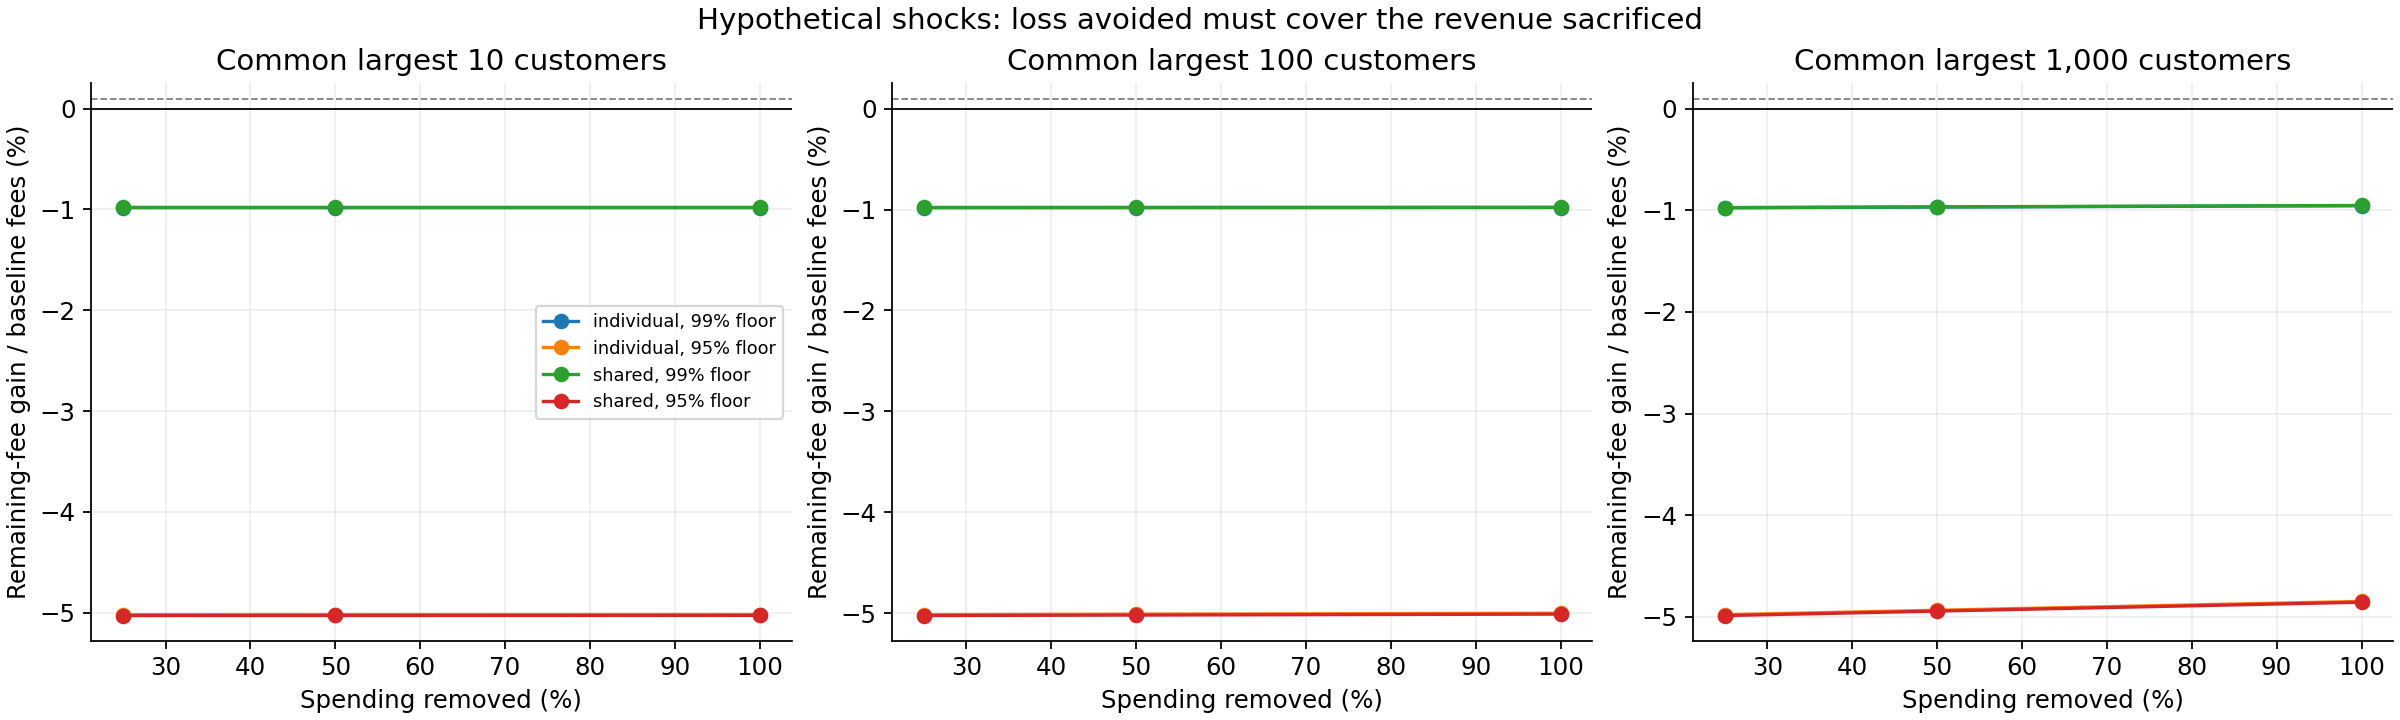

,k,origins,average_quarter_fees_lost,average_fee_share_lost_pct
0,10,8,1966.710530,0.038902
1,100,8,20335.507008,0.404281
2,1000,8,205316.431245,4.080765


In [5]:
stress = pd.read_parquet(out / 'stress_summary.parquet')
display(stress.loc[stress.comparison.eq('primary_26w_eight') & stress.severity.eq(1), ['method','retention','k','mean_gain_baseline_pct','mean_loss_avoided','mean_revenue_sacrificed','joint_successes','scenario_protection']])
display(Image(filename=str(out / 'plots/customer_stress_tradeoff.png')))

common_events = pd.read_parquet(out / 'common_stress.parquet')
baseline_events = common_events.loc[common_events.method.eq('revenue_only') & common_events.window.eq('26w') & common_events.severity.eq(1)].copy()
baseline_events['fee_share_lost_pct'] = 100 * baseline_events.loss_share
display(baseline_events.groupby('k', as_index=False).agg(
    origins=('as_of','nunique'),
    average_quarter_fees_lost=('loss','mean'),
    average_fee_share_lost_pct=('fee_share_lost_pct','mean'),
))

In [6]:
random = pd.read_parquet(out / 'random_stress_summary.parquet')
display(random.loc[random.as_of.eq('2022-06-30') & random.window.eq('26w') & random.retention.isin([1,.99]), ['method','retention','probability','mean_loss_share','sd_loss_share','p95_loss_share','worst5_mean_loss_share','moments_verified']])
display(pd.read_parquet(out / 'fragility.parquet'))
dynamics = pd.read_parquet(out / 'customer_dynamics.parquet')
display(dynamics.loc[dynamics.as_of.eq('2022-06-30') & dynamics.window.eq('26w') & dynamics.retention.isin([1,.99]), ['method','retention','customer_group','customers','historical_fees','future_fees']])

outcomes = pd.read_parquet(out / 'outcomes.parquet')
persistence = outcomes.loc[outcomes.method.eq('revenue_only') & outcomes.window.eq('26w') & outcomes.status.eq('observed')].copy()
persistence['past_top100_future_fee_share_pct'] = 100 * persistence.historical_top100_future_fee_share
persistence['future_top100_fee_share_pct'] = 100 * persistence.actual_top_100_share
display(persistence[['as_of','historical_top100_still_active','past_top100_future_fee_share_pct','future_top100_fee_share_pct']])

,method,retention,probability,mean_loss_share,sd_loss_share,p95_loss_share,worst5_mean_loss_share,moments_verified
297,revenue_only,1.00,0.01,0.010009,0.000700,0.011179,0.011438,True
298,revenue_only,1.00,0.05,0.049976,0.001605,0.052475,0.053349,True
299,revenue_only,1.00,0.10,0.099769,0.002123,0.103226,0.104160,True
306,individual,0.99,0.01,0.010005,0.000686,0.011138,0.011415,True
307,individual,0.99,0.05,0.049994,0.001577,0.052597,0.053275,True
308,individual,0.99,0.10,0.099784,0.002100,0.103061,0.104205,True
309,shared,0.99,0.01,0.010005,0.000686,0.011138,0.011415,True
310,shared,0.99,0.05,0.049994,0.001577,0.052597,0.053275,True
311,shared,0.99,0.10,0.099784,0.002100,0.103061,0.104205,True


,method,retention,window,removed_origin,remaining_mean_hhi_reduction_pct,concentration_conclusion_reverses
0,individual,0.950,26w,2022-02-28,9.673143,False
1,individual,0.980,26w,2022-02-28,6.405955,False
2,individual,0.990,26w,2022-02-28,3.855621,False
3,individual,0.995,26w,2022-02-28,1.333176,False
4,shared,0.950,26w,2022-02-28,9.661998,False
5,shared,0.980,26w,2022-02-28,6.404925,False
6,shared,0.990,26w,2022-02-28,3.858988,False
7,shared,0.995,26w,2022-02-28,1.328000,False


,method,retention,customer_group,customers,historical_fees,future_fees
396,revenue_only,1.00,returning,24081,9.355336e+06,5.742167e+06
397,revenue_only,1.00,new_to_portfolio,0,0.000000e+00,0.000000e+00
398,revenue_only,1.00,former_active_elsewhere,0,0.000000e+00,0.000000e+00
399,revenue_only,1.00,former_network_inactive,0,0.000000e+00,0.000000e+00
408,individual,0.99,returning,24081,9.254375e+06,5.688609e+06
409,individual,0.99,new_to_portfolio,0,0.000000e+00,0.000000e+00
410,individual,0.99,former_active_elsewhere,0,0.000000e+00,0.000000e+00
411,individual,0.99,former_network_inactive,0,0.000000e+00,0.000000e+00
412,shared,0.99,returning,24081,9.254375e+06,5.688609e+06
413,shared,0.99,new_to_portfolio,0,0.000000e+00,0.000000e+00


,as_of,historical_top100_still_active,past_top100_future_fee_share_pct,future_top100_fee_share_pct
0,2021-11-30,100.0,0.399014,2.015863
9,2021-12-31,100.0,0.402779,2.184971
18,2022-01-31,100.0,0.391939,2.201248
27,2022-02-28,100.0,0.407095,2.340059
45,2022-03-31,100.0,0.431689,2.157261
63,2022-04-30,100.0,0.425861,2.063404
81,2022-05-31,100.0,0.421536,1.910312
99,2022-06-30,100.0,0.425245,1.868685


## Hindsight opportunity and acceptance

Hindsight selects with future customer fees but must satisfy both historical expected-fee and actual-fee floors. It is an opportunity diagnostic, never a recommendation. Optimization bounds are numerical bounds, not confidence intervals. Customer inactivity is not proven churn or default; no actual lost principal is observed.

Customer dynamics compare the specified 26- or 52-week historical window with the following quarter. "New to the portfolio" can include returning customers after a gap; it is not proof of first-ever acquisition. The exact historical dates are exported, including the exclusion of the incomplete week before a month-end cutoff.

In the eight baseline comparisons, all 24,081 historical customers return. However, the historical largest 100 customers supply only about 0.4% of subsequent fees, whereas the subsequent period's own largest 100 supply roughly 1.9-2.3%. Continued activity does not establish persistent spending importance. The common top-100 shock group, ranked across all eligible merchants, likewise accounts for about 0.40% of subsequent baseline fees on average. This helps explain why targeting historical major-customer exposure offers limited protection in the common-shock tests.

Hindsight bounds apply to future HHI. They do not identify the portfolio best protected against a particular common-customer shock.

The hindsight comparison additionally enforces the realized fee floor. Practical selections can miss that floor after their future is revealed, so a practical point that gives up too much realized revenue is not a feasible competitor to the income-protected hindsight result.

,achieved_reduction_pct,possible_reduction_pct,actual_fee_retention_pct
retention,,,
0.950,10.001294,11.639124,95.054415
0.980,6.685130,6.799628,98.069751
0.990,4.159588,4.252013,99.049917
0.995,1.532841,1.604123,99.585128


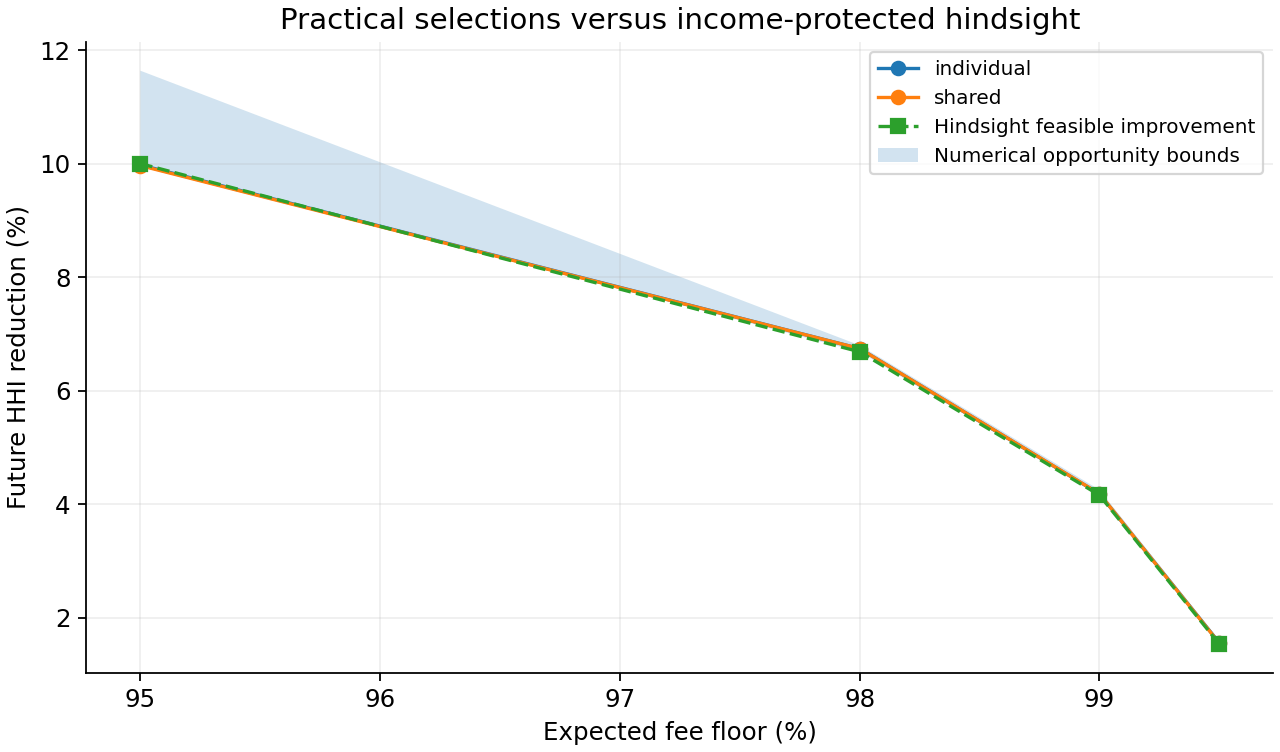

source_and_daily_reconciled    True
previous_outputs_unchanged     True
frozen_before_outcomes         True
practical_portfolios            135
optimized_portfolios            120
certified_practical             108
oracle_cases                     32
certified_oracles                22
random_moments_verified        True
september_unscored             True
common_references_identical    True
exactly_100                    True
expected_floors                True
oracle_actual_floors           True
selection_rerun                True
oracle_rerun                   True
dtype: object

In [7]:
oracle = pd.read_parquet(out / 'hindsight_only/oracle_bounds.parquet')
display(oracle.groupby('retention')[['achieved_reduction_pct','possible_reduction_pct','actual_fee_retention_pct']].mean())
display(Image(filename=str(out / 'plots/concentration_opportunity.png')))
display(pd.Series(json.loads((out / 'acceptance_checks.json').read_text())))

## Reproduction

For routine runs, use `python code/customer_concentration_serial.py all`, or replace `all` with an individual stage such as `prepare`, `select`, `evaluate`, `oracle`, `report`, `verify-select` or `verify-oracle`. This repository entry point runs one numerical worker and lowers Windows process priority. It retains the original single-threaded optimizer loop and 20-thread BLAS reductions outside that loop, under the hard resource ceilings. The May and June 2022 hindsight cases at the 95% fee floor instead retain the one-thread outer setting used by their original serial recovery run. `single_worker_execution.json` records the execution override. Run one command at a time, after any existing study process has finished.

For the interrupted laptop run, the saved local recovery helper is `python tables/analysis/customer_concentration/resume_serial.py`. It reuses validated checkpoints, completes remaining searches and independent reruns sequentially, then runs the full tests and executes this notebook. The scientific module and frozen experiment settings are unchanged; `serial_execution_settings.json` records this run's execution override.

Numerical reproducibility is distinct from identical floating-point encodings. A one-thread outer BLAS setting reproduced all May 52-week merchant selections, but changed rounding enough to alter solver paths and bounds. Restoring the original 20-thread outer BLAS setting reproduced that numerical trace exactly. Two hindsight cases (May and June 2022, 95% fee floor) were originally completed during the first one-thread serial recovery, as recorded in `serial_oracle.log`. Applying 20 threads to the last case kept its selected merchants identical but changed its solver trace and bound. The bounded diagnostic `final_oracle_thread_diagnosis.json` established that the original one-thread objective and first 16 solver steps reproduce; the serial wrapper preserves those recorded settings for both recovered cases. The scientific optimizer already limits its own loop to one thread; that remains unchanged. Both settings remain subject to the Windows memory and CPU ceilings. The single-worker verifier keeps identifiers, ranks, decisions, dates, table structure, types and missingness exact. Derived floating values use a strict relative tolerance of 1e-12 and absolute tolerance of 1e-15. Accepted differences are logged in the comparison JSONL files, and frozen result tables are preserved. Any larger discrepancy stops the pipeline and saves diagnostic copies. Parquet may normalize an object-Boolean column or discard a non-default row index. The verifier restores the original in-memory schema only when its exact original audit hash and a lossless round trip both pass; it never changes saved values or their checksums. No selection rule, optimization budget or economic threshold changes.

Run the serial stages in this order: `prepare`, `select`, `evaluate`, `oracle`, then `report`; `all` runs the sequence. The serial `verify-select` and `verify-oracle` stages independently repeat optimization. The notebook reads frozen results and regenerates reporting only. Run `python -m pytest -p no:capture code/tests -q` for the full validation suite after numerical study workers have finished.

The resource-limited restart enforces a Windows 4 GiB committed-memory ceiling for each worker and its descendants and a 20% CPU-rate ceiling. The recovery controller checks physical-memory and commit headroom and stops if they remain critically low. Independent reruns checkpoint each completed MILP call using the complete numerical input and scientific-source fingerprint; replay never uses answers from the original frozen runs. This preserves the full original numerical budgets while avoiding repeated completed solver work after an interruption. Native memory enforcement and checkpoint replay have focused regression tests. Resource controls limit this study; they cannot guarantee that unrelated applications or the operating system will remain responsive.


In [8]:
display(Markdown((out / 'findings.md').read_text(encoding='utf-8')))

# Customer concentration and revenue protection

Exactly 100 eligible merchants; expected return remains historical mean monthly gross fees. Customer concentration is measured across the entire portfolio, including customers shared between merchants. All practical selections and common shock identities were frozen before future evaluation.

## Primary results: eight 26-week tests

| Method | Fee floor | Actual fees retained | Future HHI reduction | HHI + fee wins | Downside reduction | Concentration / downside screen |
|---|---:|---:|---:|---:|---:|---|
| individual | 95% | 94.979% | +9.98% | 5/8 | -28.65% | False / False |
| individual | 98% | 98.029% | +6.74% | 4/8 | -10.74% | False / False |
| individual | 99% | 99.018% | +4.18% | 5/8 | -5.34% | False / False |
| individual | 99.5% | 99.551% | +1.56% | 4/8 | -2.93% | False / False |
| shared | 95% | 94.970% | +9.97% | 5/8 | -28.71% | False / False |
| shared | 98% | 98.027% | +6.74% | 5/8 | -10.71% | False / False |
| shared | 99% | 99.020% | +4.18% | 6/8 | -5.31% | False / False |
| shared | 99.5% | 99.552% | +1.55% | 4/8 | -2.94% | False / False |

0 of 8 practical points pass the concentration screen. 0 pass observed downside protection. 0 of 72 predeclared common-shock points pass scenario-specific revenue protection.
These are distinct findings; lower HHI alone is not evidence of greater realized profit or better protection against every shock.

## Baseline customer exposure and incremental overlap value

The September revenue-only baseline has 24,081 historically active customers and an estimated effective customer count of 21,270. Its largest 100 customers account for 1.340% of estimated fees; the largest 1,000 account for 8.834%. The shared-customer term contributes 87.35% of total estimated HHI. These are exposure descriptions, not estimated loss probabilities.

The identity map contains 499,999 customers, but only 24,081 were active at eligible merchants in this history. The baseline already reaches 100.00% of that population; 0 eligible-pool customers are outside it. Customer breadth and balanced customer fee shares are different: a portfolio can serve the same customers while changing its HHI by redistributing their fee shares. A large shared-customer contribution to HHI can coexist with low absolute concentration. The population table reports this comparison at every origin and history length.

Across primary origins, merchant concentration has mean historical-to-future Spearman rank correlation 0.992. The historical and future windows have different lengths, so the comparison describes rank persistence, not a calibrated forecast of the HHI level. All portfolio comparisons use identical future periods.

| Fee floor | Full versus individual: future HHI reduction | Full versus individual: actual fee difference |
|---|---:|---:|
| 95% | -0.013% | A$-437.40 |
| 98% | -0.001% | A$-101.23 |
| 99% | +0.003% | A$+100.67 |
| 99.5% | -0.006% | A$+84.67 |

## Numerical opportunity and robustness

108/120 practical searches and 22/32 hindsight searches meet the fixed numerical gap criterion. Uncertified searches retain explicit feasible solutions and global lower bounds. Bounds describe optimization uncertainty, not statistical confidence.

| Fee floor | Hindsight feasible HHI reduction | Upper bound on improvement | Demonstrated / ruled out / unresolved |
|---|---:|---:|---|
| 95% | 10.00% | 11.64% | 8 / 0 / 0 |
| 98% | 6.69% | 6.80% | 8 / 0 / 0 |
| 99% | 4.16% | 4.25% | 2 / 6 / 0 |
| 99.5% | 1.53% | 1.60% | 0 / 8 / 0 |

The 26/52-week comparison uses only the same five February–June origins. All values and the three non-overlapping schedules are exported; the eight overlapping quarters are not eight independent economic replications.

| History | Method | Fee floor | Actual fees retained | Future HHI reduction |
|---|---|---:|---:|---:|
| 26w | individual | 95% | 94.932% | +10.02% |
| 26w | individual | 98% | 98.007% | +6.92% |
| 26w | individual | 99% | 99.027% | +4.49% |
| 26w | individual | 99.5% | 99.617% | +1.83% |
| 26w | shared | 95% | 94.920% | +10.03% |
| 26w | shared | 98% | 98.001% | +6.93% |
| 26w | shared | 99% | 99.031% | +4.50% |
| 26w | shared | 99.5% | 99.623% | +1.82% |
| 52w | individual | 95% | 94.980% | +9.96% |
| 52w | individual | 98% | 98.007% | +6.92% |
| 52w | individual | 99% | 99.027% | +4.49% |
| 52w | individual | 99.5% | 99.617% | +1.83% |
| 52w | shared | 95% | 94.909% | +10.11% |
| 52w | shared | 98% | 97.999% | +6.93% |
| 52w | shared | 99% | 99.027% | +4.50% |
| 52w | shared | 99.5% | 99.613% | +1.82% |

## What the stress results mean

Common shocks remove 25%, 50% or 100% of the spending of the same historically identified largest 10, 100 or 1,000 customers. An improvement in remaining fees equals loss avoided minus unshocked revenue sacrificed. The common_stress table includes dollar changes and break-even severity; a break-even above 100% means even completely losing those customers would not cover the fee sacrifice.

Each portfolio’s own largest-customer removals are separate exposure diagnostics because those shocks affect different customers. The hindsight own-customer ranking is labelled explicitly and is not available to the selection algorithm.

Random customer-loss probabilities of 1%, 5% and 10% are scenarios, not calibrated churn estimates. Under independent equal-probability losses the expected lost fraction remains q, while its variance is q(1-q)HHI. Simulation moments pass a six-Monte-Carlo-standard-error check using analytical weighted-Bernoulli moments. The 500 draws do not create 500 historical observations.

Customer inactivity is identified only within this dataset. Activity elsewhere distinguishes movement outside the selected portfolio from no observed network activity. Neither establishes permanent churn or default, and prior exposure is not a measured financial loss.

The new_to_portfolio group means no fees in the specified 26- or 52-week historical exposure window, followed by fees in the future quarter. It can include customers returning after a gap and does not establish first-ever acquisition. Complete-week histories also omit the incomplete week immediately before a month-end cutoff; the exported history dates define this comparison precisely.

## Interpretation and limits

The individual-concentration control ignores customer overlap; the shared method includes it. The ablation table reports their paired future HHI and fee differences. HHI is dimensionless: merely scaling every customer’s fees down cannot improve it. Effective customer count is the reciprocal of HHI, not a count of independent real-world customers.

Concentration, downside and each stress claim are checked again after removing their most favourable origin. These are sensitivity diagnostics, not significance tests. No retention level is selected after inspecting results and the revenue-only baseline is not automatically replaced.

Categories, take rates and identity mappings are assumed stable and historically known. Selection is assumed not to change sales. Customer-loss scenarios remove spending without replacement. Gross fees exclude principal losses, fraud, funding costs, operating costs and settlement timing. September is an unscored snapshot. The short synthetic history and already examined outcomes support retrospective project evidence only; no untouched holdout or causal claim remains.

## Reproduction

Run `python code/customer_concentration_serial.py prepare`, then `select`, `evaluate`, `oracle`, and `report`; `all` runs the sequence. Use `verify-select` and `verify-oracle` for independent deterministic optimization reruns. Run `python -m pytest -p no:capture code/tests/test_customer_concentration.py -q` and the full `code/tests` suite. The notebook reads frozen artifacts and regenerates the report/plots without reselecting portfolios.
The recommended serial entry point runs one numerical worker at a time and lowers Windows process priority. It retains the original single-threaded optimizer loop and the original 20-thread BLAS reduction setting around that loop, under the 4 GiB memory and 20% CPU ceilings. The May and June 2022 hindsight cases at the 95% fee floor instead retain the one-thread outer setting used by their original serial recovery run. Run one stage command at a time. It preserves the frozen scientific settings and solver budgets. Reproduction requires exact identifiers, ranks, decisions, schema and missingness; derived floating values allow relative tolerance 1e-12 and absolute tolerance 1e-15 for documented thread-order rounding. Frozen result tables remain unchanged, and accepted differences are logged. Parquet may normalize an object-Boolean column or discard a non-default row index. The verifier restores the original in-memory schema only when its exact original audit hash and a lossless round trip both pass; it never changes saved values or their checksums. The original module can otherwise use parallel date workers.
